# OULAD: Bab 6. Graph Analytics

Graph dibangun dari **log aktivitas siswa di VLE**: siapa mengakses materi mana, dan berapa kali.

| Subbab | Isi |
|---|---|
| 6.1 | Pengembangan graph: definisi, pembangunan *vertices* dan *edges* di Spark, validasi, penyimpanan |
| 6.2 | Analisis dan insight: graph digambar dalam bentuk visual (node dan garis), lalu dibaca polanya |

Pustaka tambahan di luar PySpark: `networkx` dan `matplotlib` (`pip install networkx matplotlib`). Graph dibangun dan diagregasi di Spark. NetworkX dan matplotlib dipakai untuk menggambar graph kecil hasil agregasi atau sampel.

## 6.1 Pengembangan Graph

### 6.1.1 Definisi graph

| Istilah | Arti pada data ini |
|---|---|
| **Node** (simpul) | Dua jenis: **siswa** (kombinasi `id_student`, `code_module`, `code_presentation`, sama dengan satuan baris di bab 5) dan **materi** VLE (`id_site`) |
| **Edge** (sisi) | Siswa pernah mengakses materi |
| **Bobot edge** | Total klik siswa pada materi itu (`weight`) |
| **Derajat** (*degree*) | Jumlah koneksi sebuah node. Derajat siswa = jumlah materi berbeda yang ia akses. Derajat materi = jumlah siswa yang mengaksesnya |
| **Bipartit** | Edge hanya menghubungkan siswa dengan materi, tidak pernah siswa dengan siswa atau materi dengan materi |

Data yang tidak memuat hubungan antar-siswa (balasan forum, pertemanan) membuat graph siswa-siswa tidak dapat dibangun langsung. Karena itu graph yang dipakai adalah siswa-materi.

### 6.1.2 Pemuatan data
Data dibaca dari keluaran ETL di HDFS: log aktivitas (JSON, `raw/json/activityLog`), daftar materi (`vle.csv`), dan tabel fitur akhir untuk atribut siswa (`final_result`).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

try:
    display
except NameError:            # di luar Jupyter
    display = print

# ---- Parameter (samakan dengan ETL dan bab 5) ----
HDFS      = "hdfs://namenode:9000/data/oulad"
SUFFIX    = ""                       # "" = versi penuh (CUTOFF = None)
GRAPH_DIR = f"{HDFS}/graph"
SEED      = 42

spark = (SparkSession.builder
         .appName("oulad-graph")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.hadoop.dfs.replication", "1")      # cluster hanya punya 1 DataNode
         .getOrCreate())

schema_vle_log = StructType([
    StructField("code_module", StringType()),
    StructField("code_presentation", StringType()),
    StructField("id_student", IntegerType()),
    StructField("id_site", IntegerType()),
    StructField("date", IntegerType()),
    StructField("sum_click", IntegerType()),
])

log = spark.read.schema(schema_vle_log).json(f"{HDFS}/raw/json/activityLog")

vle = (spark.read.option("header", True).option("inferSchema", True)
       .option("nullValue", "?").csv(f"{HDFS}/raw/csv/vle.csv"))

students = (spark.read.option("header", True).option("inferSchema", True)
            .csv(f"{HDFS}/processed/features_clean{SUFFIX}")
            .select("code_module", "code_presentation", "id_student", "final_result",
                    "distinct_sites", "total_click"))

print(f"log: {log.count():,} baris | vle: {vle.count():,} materi | siswa: {students.count():,}")

log: 10,655,280 baris | vle: 6,364 materi | siswa: 32,593


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 58790)
Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/socketserver.py", line 317, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/opt/conda/lib/python3.11/socketserver.py", line 348, in process_request
    self.finish_request(request, client_address)
  File "/opt/conda/lib/python3.11/socketserver.py", line 361, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/opt/conda/lib/python3.11/socketserver.py", line 755, in __init__
    self.handle()
  File "/usr/local/spark/python/pyspark/accumulators.py", line 295, in handle
    poll(accum_updates)
  File "/usr/local/spark/python/pyspark/accumulators.py", line 267, in poll
    if self.rfile in r and func():
                           ^^^^^^
  File "/usr/local/spark/python/pyspark/accumulators.py", line 271, in accum_updates
    num_updates =

### 6.1.3 Membangun *vertices* dan *edges*
Graph disimpan sebagai dua tabel Spark, yaitu *vertices* (kolom `id`) dan *edges* (kolom `src`, `dst`). Format ini sama dengan yang dipakai pustaka graph di atas Spark (GraphFrames), sehingga dapat dipakai ulang tanpa perubahan.

Log berisi satu baris per siswa, materi, dan hari (lebih dari 10 juta baris). Untuk membentuk edge, log **diagregasi per pasangan siswa-materi**: bobot adalah jumlah klik,. Id node dibuat dari kombinasi kunci agar unik: `s_<modul>_<presentasi>_<id_student>` untuk siswa dan `m_<modul>_<presentasi>_<id_site>` untuk materi.

In [2]:
stu_id = lambda: F.concat_ws("_", F.lit("s"), F.col("code_module"), F.col("code_presentation"),
                             F.col("id_student").cast("string"))
mat_id = lambda: F.concat_ws("_", F.lit("m"), F.col("code_module"), F.col("code_presentation"),
                             F.col("id_site").cast("string"))
NULL_INT, NULL_STR = F.lit(None).cast("int"), F.lit(None).cast("string")

# ---- Vertices: siswa dan materi, dengan kolom yang sama ----
v_students = students.select(stu_id().alias("id"), F.lit("student").alias("type"),
                             "code_module", "code_presentation", "id_student", "final_result",
                             NULL_INT.alias("id_site"), NULL_STR.alias("activity_type"))
v_materials = vle.select(mat_id().alias("id"), F.lit("material").alias("type"),
                         "code_module", "code_presentation", NULL_INT.alias("id_student"),
                         NULL_STR.alias("final_result"), "id_site", "activity_type")
vertices = v_students.unionByName(v_materials)

assert v_students.select("id").distinct().count() == v_students.count(), "Id node siswa tidak unik"
assert v_materials.select("id").distinct().count() == v_materials.count(), "Id node materi tidak unik"

# ---- Edges: agregasi log per pasangan siswa-materi ----
t0 = time.time()
edges_raw = (log.groupBy("code_module", "code_presentation", "id_student", "id_site")
                .agg(F.sum("sum_click").alias("weight"))
                .select(stu_id().alias("src"), mat_id().alias("dst"),
                        "weight", "code_module", "code_presentation")
                .cache())
n_before = edges_raw.count()

# Buang edge yang ujungnya tidak ada di tabel node (seharusnya tidak ada)
edges = (edges_raw.join(v_students.select(F.col("id").alias("src")), "src", "left_semi")
                  .join(v_materials.select(F.col("id").alias("dst")), "dst", "left_semi")
                  .cache())
n_edges = edges.count()
edges_raw.unpersist()

print(f"edge terbentuk: {n_edges:,} (dari {log.count():,} baris log) dalam {time.time() - t0:.0f} s")
print(f"edge dibuang karena node tidak ditemukan: {n_before - n_edges}")

edge terbentuk: 1,960,496 (dari 10,655,280 baris log) dalam 30 s
edge dibuang karena node tidak ditemukan: 0


### 6.1.4 Validasi dan ukuran graph
Dua validasi: (1) derajat siswa di graph harus sama dengan `distinct_sites` hasil ETL, dan jumlah bobot edge siswa harus sama dengan `total_click` hasil ETL, karena keduanya dihitung dari log yang sama; (2) ukuran graph dihitung sebagai bahan pembahasan.

In [3]:
# Derajat dan total klik tiap siswa dari graph
stu_deg = (edges.groupBy("src")
                .agg(F.count("*").alias("degree"), F.sum("weight").alias("total_click"))
                .cache())

# Validasi 1: cocokkan dengan fitur ETL
chk = (students.select(stu_id().alias("src"), "distinct_sites", F.col("total_click").alias("klik_etl"))
               .join(stu_deg.withColumnRenamed("total_click", "klik_graph"), "src", "left"))
n_mismatch = chk.filter((F.coalesce("degree", F.lit(0)) != F.col("distinct_sites")) |
                        (F.coalesce("klik_graph", F.lit(0)) != F.col("klik_etl"))).count()
print(f"siswa dengan derajat atau total klik berbeda dari ETL: {n_mismatch}")
if SUFFIX == "":
    assert n_mismatch == 0, "Graph tidak cocok dengan fitur ETL"
    print("Validasi lulus.")

# Validasi 2: ukuran graph
n_s     = v_students.count()
n_m     = v_materials.count()
n_s_act = edges.select("src").distinct().count()
n_m_act = edges.select("dst").distinct().count()
n_pres  = edges.select("code_module", "code_presentation").distinct().count()

size_tbl = pd.DataFrame({"jumlah": [n_s, n_s_act, n_m, n_m_act, n_edges,
                                    n_edges / n_s_act, n_edges / n_m_act, n_pres]},
    index=["Node siswa", "  yang punya aktivitas", "Node materi", "  yang pernah diakses",
           "Edge (pasangan siswa-materi)", "Rata-rata materi per siswa aktif",
           "Rata-rata siswa per materi yang diakses", "Kombinasi modul-presentasi"])
display(size_tbl.round(1))
print("Siswa hanya mengakses materi dari modul-presentasinya sendiri, sehingga graph terdiri dari "
      f"{n_pres} bagian terpisah (satu per modul-presentasi).")

siswa dengan derajat atau total klik berbeda dari ETL: 0
Validasi lulus.


,jumlah
Node siswa,32593.0
yang punya aktivitas,29228.0
Node materi,6364.0
yang pernah diakses,6268.0
Edge (pasangan siswa-materi),1960496.0
Rata-rata materi per siswa aktif,67.1
Rata-rata siswa per materi yang diakses,312.8
Kombinasi modul-presentasi,22.0


Siswa hanya mengakses materi dari modul-presentasinya sendiri, sehingga graph terdiri dari 22 bagian terpisah (satu per modul-presentasi).


### 6.1.5 Menyimpan graph
*Vertices* dan *edges* disimpan ke HDFS (format Parquet) agar dapat dipakai ulang tanpa membangun ulang dari 10 juta baris log.

In [4]:
t0 = time.time()
vertices.write.mode("overwrite").parquet(f"{GRAPH_DIR}/vertices{SUFFIX}")
edges.write.mode("overwrite").parquet(f"{GRAPH_DIR}/edges{SUFFIX}")
print(f"graph disimpan di {GRAPH_DIR} dalam {time.time() - t0:.0f} s")

# Verifikasi dengan membaca ulang
n_v_back = spark.read.parquet(f"{GRAPH_DIR}/vertices{SUFFIX}").count()
n_e_back = spark.read.parquet(f"{GRAPH_DIR}/edges{SUFFIX}").count()
print(f"vertices: {n_v_back:,} | edges: {n_e_back:,}")
assert n_v_back == n_s + n_m and n_e_back == n_edges, "Jumlah baris hasil simpan tidak cocok"

graph disimpan di hdfs://namenode:9000/data/oulad/graph dalam 5 s
vertices: 38,957 | edges: 1,960,496


## 6.2 Analisis dan Insight

Graph penuh terlalu besar untuk digambar (puluhan ribu node dan ratusan ribu edge). Karena itu digambar **tiga bentuk yang lebih kecil**, dan masing-masing dibaca polanya.

| Gambar | Isi | Yang dilihat |
|---|---|---|
| 6.2.2 Graph siswa–materi (sampel) | Sampel siswa dan materi terpopuler dari satu modul-presentasi | Materi mana yang menjadi pusat, dan di mana posisi siswa menurut hasil akhir |
| 6.2.3 Graph antar-materi | Materi dihubungkan bila diakses siswa yang sama | Kelompok materi yang sering dipakai bersama |
| 6.2.4 Graph jenis aktivitas–hasil akhir | Ringkasan seluruh data: hasil akhir dihubungkan ke jenis aktivitas | Jenis aktivitas apa yang dominan pada tiap kelompok hasil |

**Cara membaca gambar graph:** *node* adalah titik, *edge* adalah garis penghubung. Pada gambar yang ditata otomatis (*spring layout*), node yang banyak terhubung cenderung berada di tengah, sedangkan node yang sedikit terhubung terdorong ke pinggir. Garis yang lebih tebal berarti hubungan yang lebih kuat.

### 6.2.1 Sebaran derajat
Sebelum menggambar, dilihat dulu bagaimana koneksi tersebar. *Pertanyaan: apakah koneksi merata, atau sebagian kecil materi mendominasi?*

,min,median,rata-rata,p90,p99,maks
Siswa (jumlah materi unik diakses),1.0,51.0,67.1,145.0,243.0,413.0
Materi (jumlah siswa pengakses),1.0,151.0,312.8,877.0,1645.0,2300.0


10% materi teratas (menurut jumlah pengakses) memuat 39.2% dari seluruh edge
10% materi teratas (menurut total klik) memuat 86.6% dari seluruh klik
materi diakses kurang dari 10 siswa: 952 dari 6,268 materi yang diakses
materi yang tidak pernah diakses siapa pun: 96


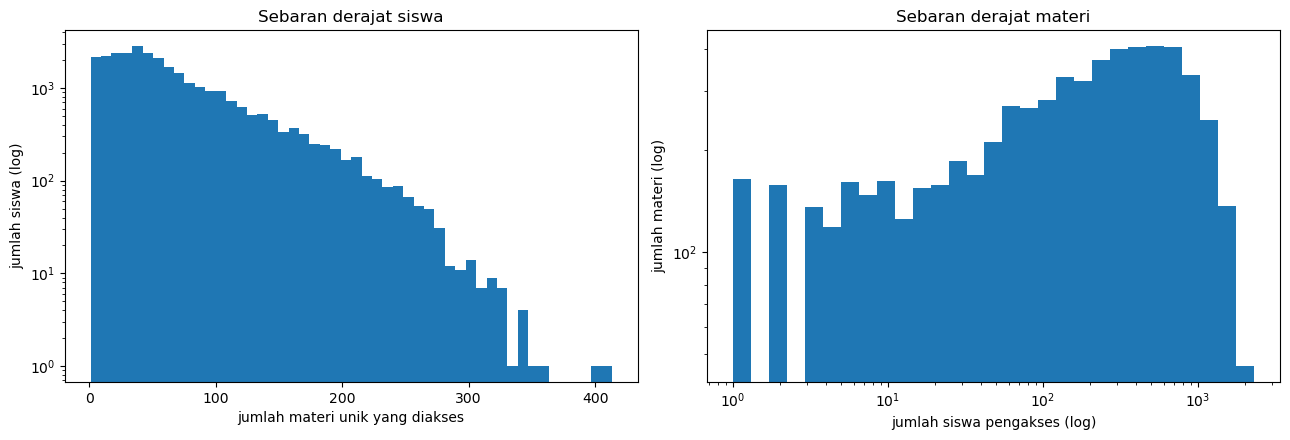

In [5]:
import networkx as nx
from matplotlib.lines import Line2D

mat_deg = (edges.groupBy("dst")
                .agg(F.count("*").alias("degree"), F.sum("weight").alias("total_click"))
                .cache())
mat_attr = v_materials.select(F.col("id").alias("dst"), "id_site", "activity_type",
                              "code_module", "code_presentation")

def describe_degree(d):
    q = d.approxQuantile("degree", [0.0, 0.5, 0.9, 0.99, 1.0], 0.001)
    return {"min": q[0], "median": q[1], "rata-rata": d.agg(F.avg("degree")).first()[0],
            "p90": q[2], "p99": q[3], "maks": q[4]}

deg_tbl = pd.DataFrame({"Siswa (jumlah materi unik diakses)": describe_degree(stu_deg),
                        "Materi (jumlah siswa pengakses)":    describe_degree(mat_deg)}).T
display(deg_tbl.round(1))

stu_pd, mat_pd = stu_deg.toPandas(), mat_deg.toPandas()

def top_share(series, frac=0.10):
    s = series.sort_values(ascending=False).to_numpy()
    k = max(1, int(np.ceil(len(s) * frac)))
    return s[:k].sum() / s.sum()

print(f"10% materi teratas (menurut jumlah pengakses) memuat {top_share(mat_pd['degree']) * 100:.1f}% dari seluruh edge")
print(f"10% materi teratas (menurut total klik) memuat {top_share(mat_pd['total_click']) * 100:.1f}% dari seluruh klik")
print(f"materi diakses kurang dari 10 siswa: {(mat_pd['degree'] < 10).sum():,} dari {len(mat_pd):,} materi yang diakses")
print(f"materi yang tidak pernah diakses siapa pun: {n_m - len(mat_pd):,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(stu_pd["degree"], bins=50)
ax[0].set_yscale("log"); ax[0].set_xlabel("jumlah materi unik yang diakses"); ax[0].set_ylabel("jumlah siswa (log)")
ax[0].set_title("Sebaran derajat siswa")
bins = np.logspace(0, np.log10(max(mat_pd["degree"].max(), 2)), 30)
ax[1].hist(mat_pd["degree"], bins=bins)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("jumlah siswa pengakses (log)"); ax[1].set_ylabel("jumlah materi (log)")
ax[1].set_title("Sebaran derajat materi")
plt.tight_layout(); plt.show()

### 6.2.2 Gambar 1: graph siswa–materi (sampel satu modul-presentasi)
Diambil modul-presentasi terbesar. Yang digambar: **30 materi dengan pengakses terbanyak** dan **sampel siswa yang seimbang per hasil akhir** (20 per kelas), dengan garis bila siswa mengakses materi itu. Siswa dari tiap kelas diambil sama banyak agar tampilan tidak didominasi kelas besar.

- **Lingkaran** = siswa, warna menurut hasil akhir. **Kotak** = materi, warna menurut jenis aktivitas, ukuran menurut jumlah siswa pengaksesnya.
- Siswa yang tidak mengakses satu pun dari 30 materi itu tidak tergambar, dan jumlahnya dicetak.

modul-presentasi yang digambar: FFF 2013J
digambar: 72 siswa, 30 materi, 1874 garis
siswa sampel tanpa koneksi ke 30 materi teratas (tidak tergambar): 8


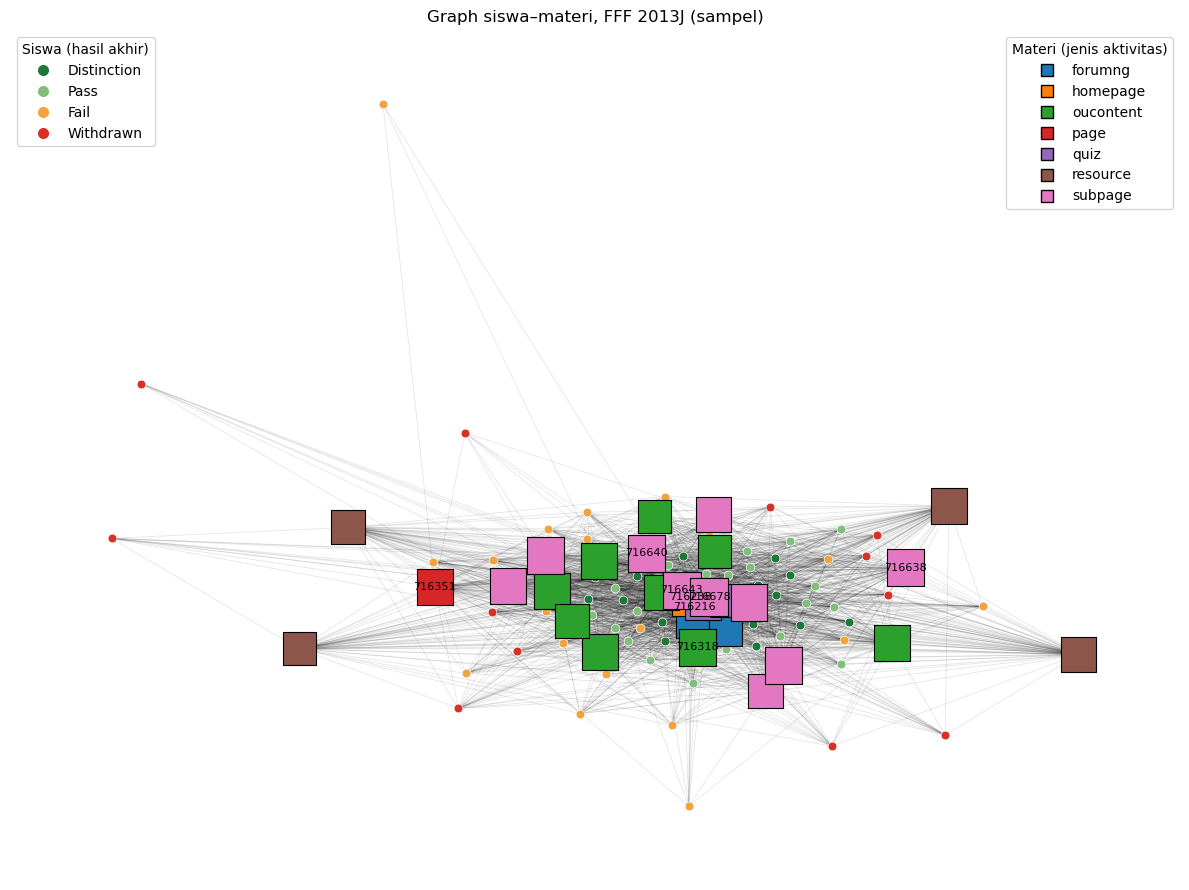


Rata-rata jumlah materi (dari 30 teratas) yang diakses siswa sampel:


,mean,median
final_result,,
Distinction,29.5,30.0
Pass,28.2,29.0
Fail,23.9,25.5
Withdrawn,12.0,9.5


In [6]:
OUT_COLORS = {"Distinction": "#1b7837", "Pass": "#7fbf7b", "Fail": "#f1a340", "Withdrawn": "#d73027"}

focus = (edges.groupBy("code_module", "code_presentation").count().orderBy(F.desc("count")).first())
FOCUS = (focus["code_module"], focus["code_presentation"])
is_focus = (F.col("code_module") == FOCUS[0]) & (F.col("code_presentation") == FOCUS[1])
edges_f = edges.filter(is_focus)
print(f"modul-presentasi yang digambar: {FOCUS[0]} {FOCUS[1]}")

N_TOP_MAT, N_PER_CLASS = 30, 20

top_mat_all = (mat_deg.join(mat_attr, "dst").filter(is_focus).orderBy(F.desc("degree")).limit(40)
                      .select("dst", "id_site", "activity_type", "degree").toPandas())
top_mat_pd = top_mat_all.head(N_TOP_MAT)

stu_focus = v_students.filter(is_focus).select(F.col("id").alias("src"), "final_result").toPandas()
sample = pd.concat([g.sample(min(N_PER_CLASS, len(g)), random_state=SEED)
                    for _, g in stu_focus.groupby("final_result")])

sub = (edges_f.filter(F.col("src").isin(list(sample["src"])) & F.col("dst").isin(list(top_mat_pd["dst"])))
              .select("src", "dst", "weight").toPandas())

G1 = nx.Graph()
G1.add_weighted_edges_from(sub.itertuples(index=False, name=None))
stu_nodes = [n for n in G1 if n.startswith("s_")]
mat_nodes = [n for n in G1 if n.startswith("m_")]
print(f"digambar: {len(stu_nodes)} siswa, {len(mat_nodes)} materi, {G1.number_of_edges()} garis")
print(f"siswa sampel tanpa koneksi ke 30 materi teratas (tidak tergambar): {len(sample) - len(stu_nodes)}")

pos = nx.spring_layout(G1, seed=SEED, k=0.35, iterations=100)
res_map  = dict(zip(sample["src"], sample["final_result"]))
mat_info = top_mat_pd.set_index("dst")
act_list = sorted(top_mat_pd["activity_type"].unique())
act_color = {a: plt.get_cmap("tab10")(i % 10) for i, a in enumerate(act_list)}

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(G1, pos, ax=ax, alpha=0.10, width=0.6)
for k, c in OUT_COLORS.items():
    nodes = [n for n in stu_nodes if res_map.get(n) == k]
    nx.draw_networkx_nodes(G1, pos, nodelist=nodes, node_color=c, node_size=40, ax=ax,
                           edgecolors="white", linewidths=0.5)
dmax = mat_info["degree"].max()
for a in act_list:
    nodes = [n for n in mat_nodes if mat_info.loc[n, "activity_type"] == a]
    nx.draw_networkx_nodes(G1, pos, nodelist=nodes, node_color=[act_color[a]], node_shape="s",
                           node_size=[60 + 700 * mat_info.loc[n, "degree"] / dmax for n in nodes],
                           ax=ax, edgecolors="black", linewidths=0.8)
top_lab = mat_info.nlargest(8, "degree").index
nx.draw_networkx_labels(G1, pos, labels={n: str(mat_info.loc[n, "id_site"]) for n in top_lab if n in G1},
                        font_size=8, ax=ax)

h1 = [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=9, label=k)
      for k, c in OUT_COLORS.items()]
h2 = [Line2D([0], [0], marker="s", color="w", markerfacecolor=act_color[a], markeredgecolor="black",
             markersize=9, label=a) for a in act_list]
leg1 = ax.legend(handles=h1, title="Siswa (hasil akhir)", loc="upper left")
ax.add_artist(leg1)
ax.legend(handles=h2, title="Materi (jenis aktivitas)", loc="upper right")
ax.set_title(f"Graph siswa–materi, {FOCUS[0]} {FOCUS[1]} (sampel)")
ax.axis("off"); plt.tight_layout(); plt.show()

# Pendukung angka untuk gambar: rata-rata koneksi siswa sampel ke 30 materi teratas
sample["koneksi"] = sample["src"].map(dict(G1.degree())).fillna(0)
order = [k for k in OUT_COLORS if k in set(sample["final_result"])]
print("\nRata-rata jumlah materi (dari 30 teratas) yang diakses siswa sampel:")
display(sample.groupby("final_result")["koneksi"].agg(["mean", "median"]).reindex(order).round(1))

In [12]:
from pyspark.sql import functions as F

MODULE = "FFF"       # Ganti dengan code_module
PRESENTATION = "2013J"  # Ganti dengan code_presentation

# Filter berdasarkan module dan presentation
e = edges.filter(
    (F.col("code_module") == MODULE) &
    (F.col("code_presentation") == PRESENTATION)
)

# Ambil 20 mahasiswa dengan total klik tertinggi
top_students = (
    e.groupBy("src")
     .agg(F.sum("weight").alias("total_clicks"))
     .orderBy(F.desc("total_clicks"))
     .limit(5)
     .select("src")
)

# Ambil 20 materi dengan total klik tertinggi
top_materials = (
    e.groupBy("dst")
     .agg(F.sum("weight").alias("total_clicks"))
     .orderBy(F.desc("total_clicks"))
     .limit(8)
     .select("dst")
)

# Ambil edge yang menghubungkan kedua kelompok tersebut
e_plot = (
    e.join(top_students, "src", "left_semi")
     .join(top_materials, "dst", "left_semi")
)

# Collect hanya subset untuk visualisasi
edges_pd = e_plot.toPandas()

# Ambil informasi node yang digunakan
node_ids = (
    edges_pd["src"].tolist() +
    edges_pd["dst"].tolist()
)

vertices_pd = (
    vertices.filter(F.col("id").isin(node_ids))
            .toPandas()
)

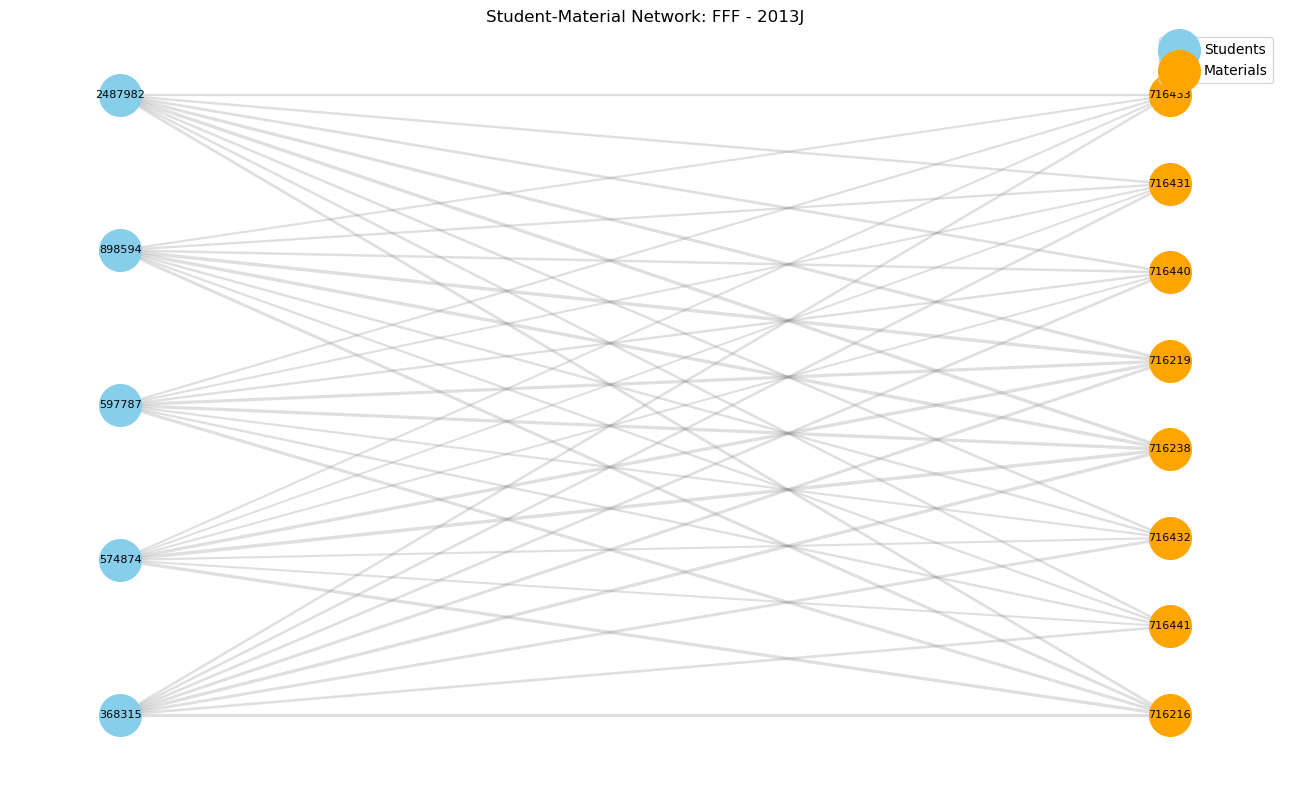

In [14]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.Graph()

# Tambahkan node
for _, row in vertices_pd.iterrows():
    if row["type"] == "student":
        G.add_node(
            row["id"],
            bipartite=0,
            label=str(int(row["id_student"]))
        )
    else:
        G.add_node(
            row["id"],
            bipartite=1,
            label=f'{int(row["id_site"])}'
        )

# Tambahkan edge
for _, row in edges_pd.iterrows():
    G.add_edge(
        row["src"],
        row["dst"],
        weight=row["weight"]
    )

students_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == 0
]

materials_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == 1
]

pos = nx.bipartite_layout(G, students_nodes)

plt.figure(figsize=(13, 8))

# Nodes
nx.draw_networkx_nodes(
    G, pos,
    nodelist=students_nodes,
    node_color="skyblue",
    node_size=900,
    label="Students"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=materials_nodes,
    node_color="orange",
    node_size=900,
    label="Materials"
)

# Edge berdasarkan bobot
weights = [G[u][v]["weight"] for u, v in G.edges()]

widths = [
    0.5 + 2 * np.log1p(w) / np.log1p(max(weights))
    for w in weights
]

nx.draw_networkx_edges(
    G, pos,
    width=widths,
    alpha=0.25,
    edge_color="gray"
)

# Labels
labels = nx.get_node_attributes(G, "label")

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=8
)

plt.title(f"Student-Material Network: {MODULE} - {PRESENTATION}")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

**Pendukung dari seluruh graph (bukan hanya sampel):** sebaran jumlah materi unik yang diakses siswa menurut hasil akhir.

,n_siswa,tanpa_aktivitas,median_materi_unik,rata2_materi_unik,median_klik
final_result,,,,,
Distinction,3024,0,82.0,102.4,1896.0
Pass,12361,3,73.0,89.1,1343.0
Fail,7052,374,32.0,43.1,317.0
Withdrawn,10156,2988,14.0,24.2,89.0


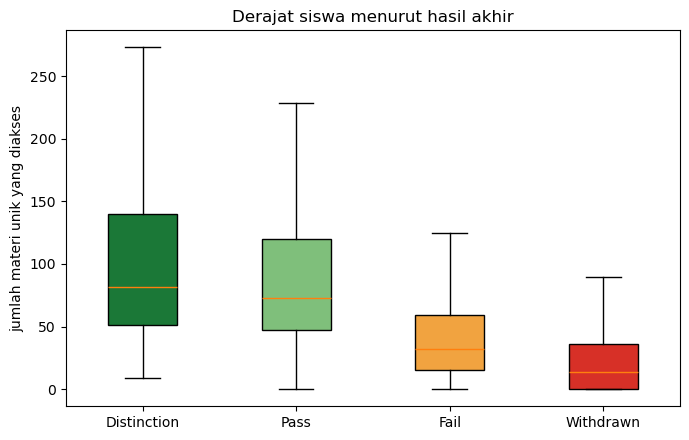

In [7]:
stu_all = (v_students.select(F.col("id").alias("src"), "final_result")
           .join(stu_deg, "src", "left")
           .fillna(0, subset=["degree", "total_click"])
           .toPandas())

order_all = [k for k in OUT_COLORS if k in set(stu_all["final_result"])]
res_tbl = (stu_all.groupby("final_result")
           .agg(n_siswa=("src", "size"),
                tanpa_aktivitas=("degree", lambda s: int((s == 0).sum())),
                median_materi_unik=("degree", "median"),
                rata2_materi_unik=("degree", "mean"),
                median_klik=("total_click", "median"))
           .reindex(order_all))
display(res_tbl.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
bp = ax.boxplot([stu_all.loc[stu_all["final_result"] == k, "degree"] for k in order_all],
                showfliers=False, patch_artist=True)
for patch, k in zip(bp["boxes"], order_all):
    patch.set_facecolor(OUT_COLORS[k])
ax.set_xticklabels(order_all)
ax.set_ylabel("jumlah materi unik yang diakses")
ax.set_title("Derajat siswa menurut hasil akhir")
plt.tight_layout(); plt.show()

### 6.2.3 Gambar 2: graph antar-materi
Graph kedua mengubah sudut pandang: yang menjadi node adalah **materi**. Dua materi dihubungkan bila **diakses oleh siswa yang sama**, dengan kekuatan hubungan diukur dengan *Jaccard*:

`Jaccard = siswa yang mengakses keduanya / siswa yang mengakses salah satunya`

Nilainya 0 sampai 1. Ukuran ini dipakai agar materi populer tidak otomatis tampak terhubung dengan semua materi: dua materi hanya terhubung kuat bila pengaksesnya memang banyak yang sama.

Diambil **40 materi terpopuler** pada modul-presentasi yang sama. Agar gambarnya terbaca, **setiap materi hanya dihubungkan ke 3 materi yang paling mirip pengaksesnya**. Warna = jenis aktivitas, ukuran = jumlah siswa pengakses, garis lebih tebal = hubungan lebih kuat. Materi yang berkumpul membentuk kelompok yang sering dipakai bersama.

digambar: 40 materi, 98 hubungan (Jaccard 0.73 sampai 0.99)


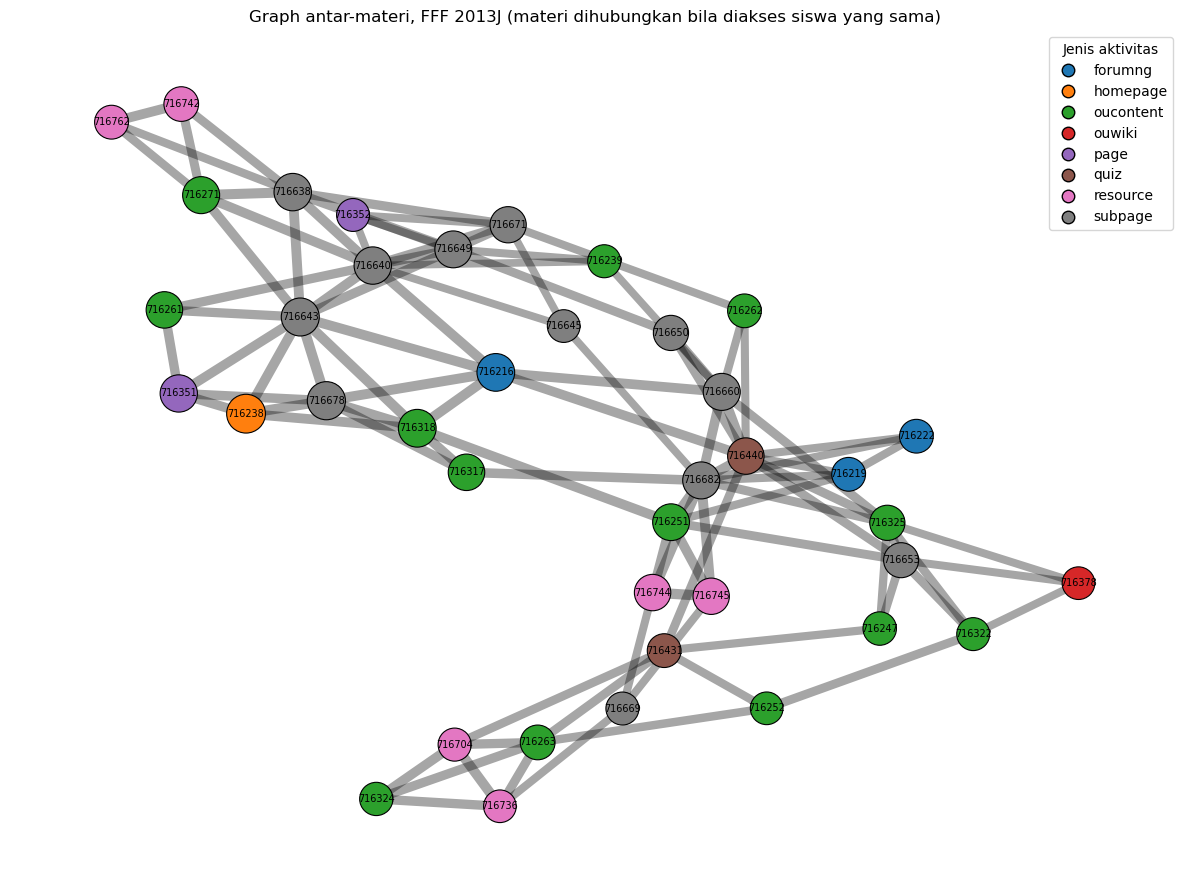


10 pasangan materi dengan hubungan terkuat:


,materi_1,jenis_1,materi_2,jenis_2,shared,jaccard
200,716744,resource,716745,resource,1806,0.992
320,716643,subpage,716678,subpage,1995,0.987
14,716318,oucontent,716678,subpage,1971,0.977
748,716318,oucontent,716643,subpage,1957,0.971
167,716271,oucontent,716638,subpage,1881,0.970
611,716682,subpage,716744,resource,1816,0.964
286,716440,quiz,716660,subpage,1822,0.964
226,716238,homepage,716678,subpage,2016,0.962
246,716682,subpage,716745,resource,1810,0.961
227,716216,forumng,716678,subpage,1947,0.957


Hubungan antar-materi yang sejenis aktivitas: 29% dari 98 hubungan


In [8]:
N_NET, K_NN = 40, 3
net_mat = top_mat_all.head(N_NET)

e_top = (edges_f.join(F.broadcast(spark.createDataFrame(net_mat[["dst"]])), "dst", "left_semi")
                .select("src", "dst").cache())
a, b = e_top.alias("a"), e_top.alias("b")
pairs = (a.join(b, F.col("a.src") == F.col("b.src"))
          .where(F.col("a.dst") < F.col("b.dst"))
          .groupBy(F.col("a.dst").alias("m1"), F.col("b.dst").alias("m2"))
          .agg(F.count("*").alias("shared")).toPandas())

deg = net_mat.set_index("dst")["degree"]
pairs["jaccard"] = pairs["shared"] / (pairs["m1"].map(deg) + pairs["m2"].map(deg) - pairs["shared"])
top_pairs = pairs.sort_values("jaccard", ascending=False)

# Tiap materi dihubungkan ke K_NN materi yang paling mirip (hubungan dua arah digabung)
both = pd.concat([pairs.rename(columns={"m1": "a", "m2": "b"}),
                  pairs.rename(columns={"m1": "b", "m2": "a"})])
nearest = both.sort_values("jaccard", ascending=False).groupby("a").head(K_NN)

H = nx.Graph()
for r in nearest.itertuples():
    H.add_edge(r.a, r.b, jaccard=r.jaccard, shared=r.shared)
info = net_mat.set_index("dst")
jvals = [d["jaccard"] for _, _, d in H.edges(data=True)]
print(f"digambar: {H.number_of_nodes()} materi, {H.number_of_edges()} hubungan "
      f"(Jaccard {min(jvals):.2f} sampai {max(jvals):.2f})")

pos = nx.spring_layout(H, weight="jaccard", seed=SEED, k=0.8, iterations=200)
act_list2 = sorted(info.loc[list(H.nodes), "activity_type"].unique())
act_color2 = {a_: plt.get_cmap("tab10")(i % 10) for i, a_ in enumerate(act_list2)}
dmax = info["degree"].max()
jmax = max(jvals)

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.35,
                       width=[0.4 + 7 * H[u][v]["jaccard"] / jmax for u, v in H.edges()])
nx.draw_networkx_nodes(H, pos, ax=ax,
                       node_color=[act_color2[info.loc[n, "activity_type"]] for n in H.nodes],
                       node_size=[80 + 700 * info.loc[n, "degree"] / dmax for n in H.nodes],
                       edgecolors="black", linewidths=0.8)
nx.draw_networkx_labels(H, pos, labels={n: str(info.loc[n, "id_site"]) for n in H.nodes},
                        font_size=7, ax=ax)
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markeredgecolor="black",
                          markersize=9, label=a_) for a_, c in act_color2.items()],
          title="Jenis aktivitas", loc="upper right")
ax.set_title(f"Graph antar-materi, {FOCUS[0]} {FOCUS[1]} (materi dihubungkan bila diakses siswa yang sama)")
ax.axis("off"); plt.tight_layout(); plt.show()

print("\n10 pasangan materi dengan hubungan terkuat:")
tp = top_pairs.head(10).copy()
tp["materi_1"] = tp["m1"].map(info["id_site"]);  tp["jenis_1"] = tp["m1"].map(info["activity_type"])
tp["materi_2"] = tp["m2"].map(info["id_site"]);  tp["jenis_2"] = tp["m2"].map(info["activity_type"])
display(tp[["materi_1", "jenis_1", "materi_2", "jenis_2", "shared", "jaccard"]].round(3))
print("Hubungan antar-materi yang sejenis aktivitas: "
      f"{np.mean([info.loc[u, 'activity_type'] == info.loc[v, 'activity_type'] for u, v in H.edges()]) * 100:.0f}% dari {H.number_of_edges()} hubungan")

### 6.2.4 Gambar 3: graph jenis aktivitas dan hasil akhir
Graph ketiga memakai **seluruh data**, diringkas dulu di Spark: node kiri adalah **hasil akhir** (4 kelompok), node kanan adalah **jenis aktivitas** (8 teratas, sisanya digabung sebagai `lainnya`). Tebal garis menunjukkan **porsi klik** kelompok itu pada jenis aktivitas tersebut (jumlah porsi tiap kelompok = 100%).

Tabel di bawah gambar memuat **rasio terhadap rata-rata**: porsi kelompok dibagi porsi seluruh siswa. Rasio di atas 1 berarti jenis aktivitas itu lebih dominan pada kelompok tersebut dibanding rata-rata siswa.

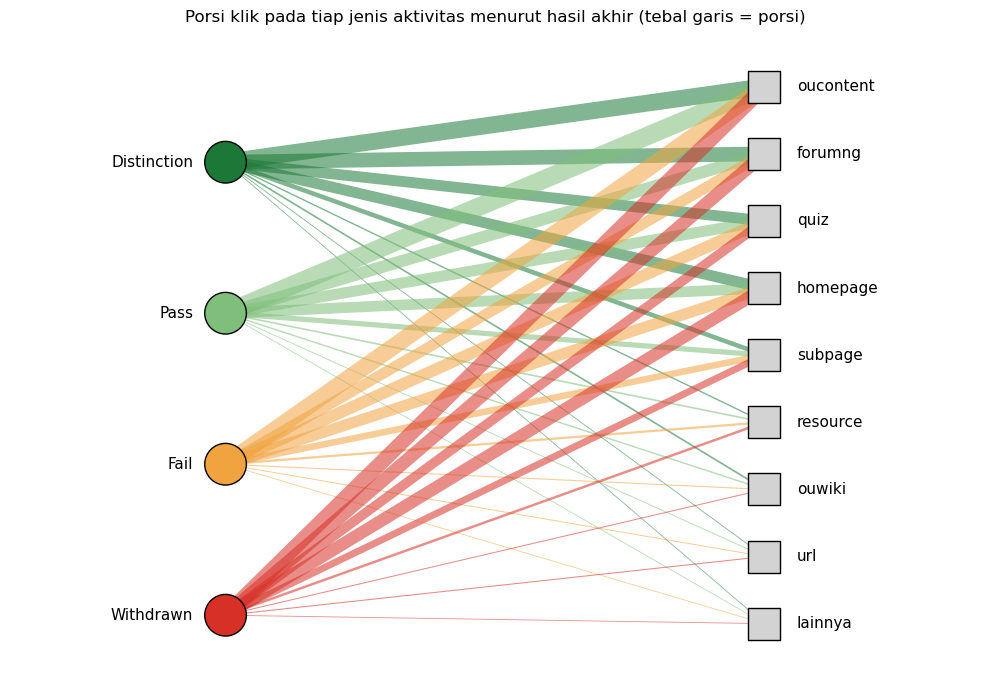

Porsi klik (%) per kelompok hasil akhir:


tipe,oucontent,forumng,quiz,homepage,subpage,resource,ouwiki,url,lainnya
final_result,,,,,,,,,
Distinction,27.0,23.4,17.4,17.5,7.2,2.2,2.7,1.3,1.2
Pass,29.6,19.4,17.7,17.2,8.4,2.7,2.3,1.4,1.3
Fail,26.8,17.3,19.1,18.0,10.5,3.7,1.7,1.6,1.3
Withdrawn,24.1,20.9,15.4,19.8,11.0,4.0,1.7,1.7,1.3


Rasio terhadap rata-rata seluruh siswa (>1 = lebih dominan dibanding rata-rata):


tipe,oucontent,forumng,quiz,homepage,subpage,resource,ouwiki,url,lainnya
final_result,,,,,,,,,
Distinction,0.95,1.16,0.99,1.00,0.84,0.79,1.19,0.92,0.96
Pass,1.05,0.97,1.01,0.98,0.97,0.96,1.02,0.98,1.02
Fail,0.95,0.86,1.09,1.03,1.22,1.30,0.76,1.11,0.97
Withdrawn,0.85,1.04,0.87,1.13,1.28,1.42,0.74,1.22,1.01


In [9]:
act_out = (edges.join(mat_attr.select("dst", "activity_type"), "dst")
                .join(v_students.select(F.col("id").alias("src"), "final_result"), "src")
                .groupBy("final_result", "activity_type")
                .agg(F.sum("weight").alias("klik")).toPandas())

TOP_T = 8
overall = act_out.groupby("activity_type")["klik"].sum().sort_values(ascending=False)
top_types = overall.head(TOP_T).index.tolist()
act_out["tipe"] = np.where(act_out["activity_type"].isin(top_types), act_out["activity_type"], "lainnya")
agg = act_out.groupby(["final_result", "tipe"])["klik"].sum().reset_index()
agg["share"] = agg["klik"] / agg.groupby("final_result")["klik"].transform("sum")
overall_share = agg.groupby("tipe")["klik"].sum() / agg["klik"].sum()
agg["rasio"] = agg["share"] / agg["tipe"].map(overall_share)

types_order = top_types + (["lainnya"] if "lainnya" in set(agg["tipe"]) else [])
res_order = [k for k in OUT_COLORS if k in set(agg["final_result"])]

B = nx.Graph()
for r in agg.itertuples():
    B.add_edge(("H", r.final_result), ("T", r.tipe), share=r.share)
pos = {("H", k): (0, -i * 2.0) for i, k in enumerate(res_order)}
pos.update({("T", t): (1, -i * (len(res_order) * 2.0 / len(types_order)) + 1.0)
            for i, t in enumerate(types_order)})

fig, ax = plt.subplots(figsize=(10, 7))
for k in res_order:
    es = [(u, v) for u, v in B.edges() if ("H", k) in (u, v)]
    nx.draw_networkx_edges(B, pos, edgelist=es, ax=ax, edge_color=OUT_COLORS[k], alpha=0.55,
                           width=[B[u][v]["share"] * 45 for u, v in es])
nx.draw_networkx_nodes(B, pos, nodelist=[("H", k) for k in res_order], ax=ax, node_size=900,
                       node_color=[OUT_COLORS[k] for k in res_order], edgecolors="black")
nx.draw_networkx_nodes(B, pos, nodelist=[("T", t) for t in types_order], ax=ax, node_size=500,
                       node_color="lightgray", node_shape="s", edgecolors="black")
for k in res_order:
    ax.text(-0.06, pos[("H", k)][1], k, ha="right", va="center", fontsize=11)
for t in types_order:
    ax.text(1.06, pos[("T", t)][1], t, ha="left", va="center", fontsize=11)
ax.set_xlim(-0.4, 1.4)
ax.set_title("Porsi klik pada tiap jenis aktivitas menurut hasil akhir (tebal garis = porsi)")
ax.axis("off"); plt.tight_layout(); plt.show()

share_tbl = (agg.pivot(index="final_result", columns="tipe", values="share")
                .reindex(index=res_order, columns=types_order) * 100)
ratio_tbl = (agg.pivot(index="final_result", columns="tipe", values="rasio")
                .reindex(index=res_order, columns=types_order))
print("Porsi klik (%) per kelompok hasil akhir:")
display(share_tbl.round(1))
print("Rasio terhadap rata-rata seluruh siswa (>1 = lebih dominan dibanding rata-rata):")
display(ratio_tbl.round(2))

### Ringkasan bahan analisis

| Gambar | Pertanyaan | Yang dilihat dari gambar dan tabel |
|---|---|---|
| 6.2.1 | Merata atau timpang? | Median vs p99 vs maks, persentase edge dan klik pada 10% materi teratas |
| 6.2.2 | Materi mana yang menjadi pusat, dan di mana posisi siswa menurut hasil akhir? | Kotak besar di tengah, posisi warna siswa (tengah atau pinggir), rata-rata koneksi per kelompok |
| 6.2.3 | Apakah ada kelompok materi yang dipakai bersama? | Kumpulan node yang berdekatan, warna di dalam kumpulan (satu jenis atau campuran), persentase pasangan sejenis |
| 6.2.4 | Jenis aktivitas apa yang dominan pada tiap hasil akhir? | Garis paling tebal tiap kelompok, rasio di atas dan di bawah 1 |

Semua pola yang terlihat adalah hubungan, bukan sebab-akibat: siswa yang aktif cenderung mengakses banyak materi dan juga cenderung lulus.